#Practica 1: Introducción a Tensorflow 2
Sandra Paz Grau


In [ ]:
import tensorflow as tf
print(tf.__version__)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import time

2.20.0


## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos

![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [ ]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [ ]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [ ]:
h=model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9247 - loss: 0.2616
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9660 - loss: 0.1149
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9763 - loss: 0.0794
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9823 - loss: 0.0587
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9855 - loss: 0.0463


## Evaluación
Una vez entrenada la red neuronal, prodremos obtener las medidas de rendimiento especificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [ ]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9894 - loss: 0.0367
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9741 - loss: 0.0830


[0.08295880258083344, 0.9740999937057495]

In [ ]:
def numeroErroresMatrizConfusion(model, x_test, y_test):

  #Hacemos las predicciones sobre el conjunto de test
  predicciones_prob = model.predict(x_test)

  #Cogemos la clase que tiene mas probabilidad que sea la imagen según el modelo
  predicciones_clases = np.argmax(predicciones_prob, axis=1)

  #Calculamos el número total de errores
  errores_test = np.sum(predicciones_clases != y_test)
  print(f"Número total de errores en test: {errores_test} (de {len(y_test)} imágenes)")

  #Generamos la matriz de confusión
  matriz_conf = confusion_matrix(y_test, predicciones_clases)

  plt.figure(figsize=(8,6))
  sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues')
  plt.title('Matriz de Confusión en Test')
  plt.xlabel('Dígito Predicho (por el modelo)')
  plt.ylabel('Dígito Real')
  plt.show()

In [ ]:
def grafica_accuracy_perdida(h):
  plt.figure(figsize=(12, 4))

  # Gráfica 1: Accuracy
  plt.subplot(1, 2, 1)
  plt.plot(h.history['accuracy'], label='Entrenamiento', marker='o')
  plt.plot(h.history['val_accuracy'], label='Validación', marker='o')
  plt.title('Evolución de la Exactitud')
  plt.xlabel('Épocas')
  plt.ylabel('Exactitud (Accuracy)')
  plt.legend()

  # Gráfica 2: Loss
  plt.subplot(1, 2, 2)
  plt.plot(h.history['loss'], label='Entrenamiento', marker='o')
  plt.plot(h.history['val_loss'], label='Validación', marker='o')
  plt.title('Evolución de la Pérdida')
  plt.xlabel('Épocas')
  plt.ylabel('Pérdida (Loss)')
  plt.legend()

  plt.show()

# **Pruebas de experimentos**
A continuación vamos a hacer serie de experimentos, variando los distintos parametros del modelo para ver como se comporta, con el objetivo de encontrar el mejor modelo posible.

# Experimento 1


En este experimento probaremos con un optimizador Adam, función de perdida entropía y las funciones de activación relu y softmax.

**Resultados:** al evaluar este primer modelo base, los resultados muestran una convergencia rápida y muy estable, logrando una alta exactitud en la clasificación de imágenes nuevas. Si observamos las gráficas de evolución, las curvas de aprendizaje descienden de manera suave y conjunta tanto en entrenamiento como en validación, demostrando que la red es capaz de extraer los patrones correctamente en un tiempo de ejecución bastante reducido y sin presentar ningún síntoma de sobreajuste.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9187 - loss: 0.2840 - val_accuracy: 0.9544 - val_loss: 0.1600
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9613 - loss: 0.1280 - val_accuracy: 0.9642 - val_loss: 0.1220
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9743 - loss: 0.0867 - val_accuracy: 0.9671 - val_loss: 0.1109
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9818 - loss: 0.0632 - val_accuracy: 0.9671 - val_loss: 0.1112
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9870 - loss: 0.0469 - val_accuracy: 0.9668 - val_loss: 0.1106

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9789 - loss: 0.0653

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9683 - loss: 0.1033


[0.10332747548818588, 0.9682999849319458]


Tiempo invertido en el entrenamiento: 38.42 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 317 (de 10000 imágenes)


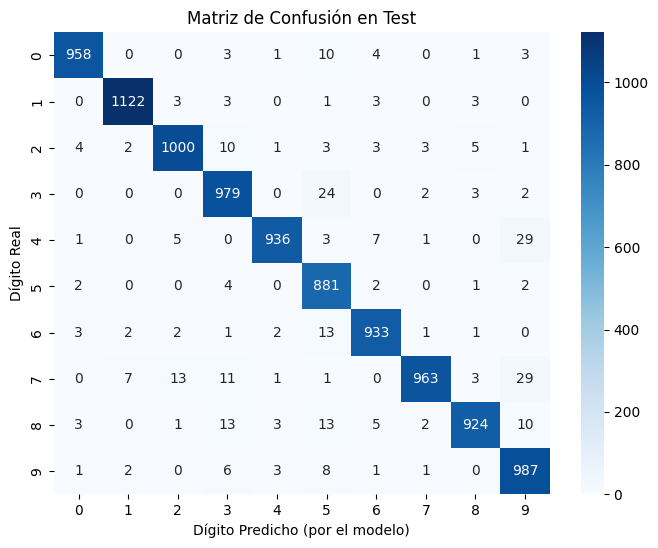

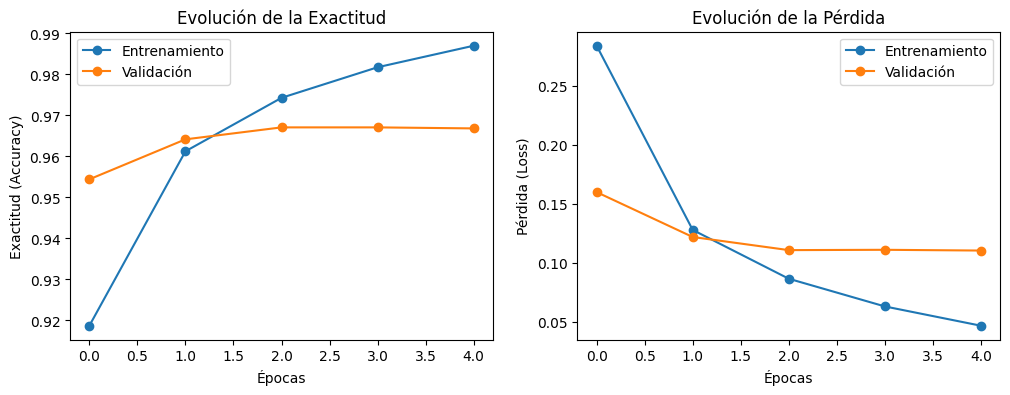

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 2
Este experimento cambiaremos solo el numero de epocas en comparación con el anterior, utilizando 10 epocas.

**Resultados:** al duplicar el número de épocas respecto a nuestro modelo base, el tiempo total de entrenamiento se incrementa de forma notable. Aunque el modelo logra reducir muy ligeramente la cantidad final de errores, las gráficas de evolución revelan un claro problema de sobreajuste: la curva de pérdida de validación se estanca rápidamente a mitad del proceso, mientras que la de entrenamiento continúa descendiendo hacia cero. Esto demuestra que la red comienza a memorizar los datos en lugar de aprender a generalizar, confirmando que un entrenamiento tan prolongado resulta excesivo para esta configuración.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
#Cambiamos las epocas para que tenga 10
h=model.fit(x_train, y_train, epochs=10, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9156 - loss: 0.2923 - val_accuracy: 0.9515 - val_loss: 0.1673
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9618 - loss: 0.1295 - val_accuracy: 0.9616 - val_loss: 0.1294
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9744 - loss: 0.0862 - val_accuracy: 0.9643 - val_loss: 0.1170
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9826 - loss: 0.0618 - val_accuracy: 0.9663 - val_loss: 0.1121
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9875 - loss: 0.0457 - val_accuracy: 0.9657 - val_loss: 0.1139
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9912 - loss: 0.0340 - val_accuracy: 0.9657 - val_loss: 0.1128
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9938 - loss: 0.0254 - val_accuracy: 0.9693 - val_loss: 0.1081
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9951 - loss: 0.0203 - 

[0.0975271612405777, 0.9750000238418579]


Tiempo invertido en el entrenamiento: 71.06 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 250 (de 10000 imágenes)


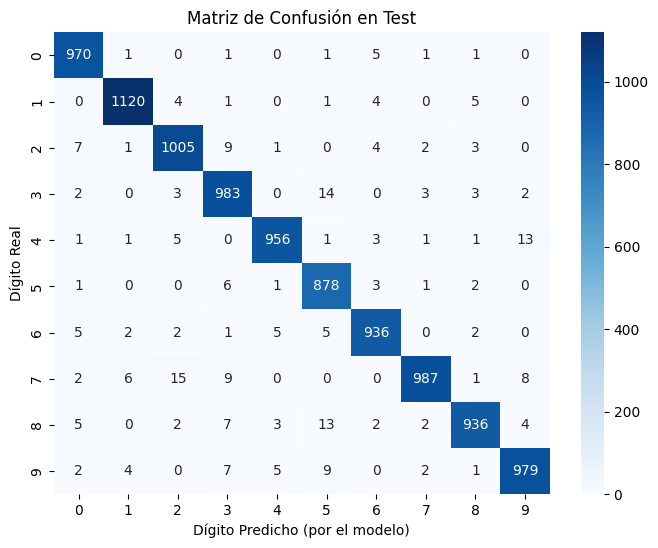

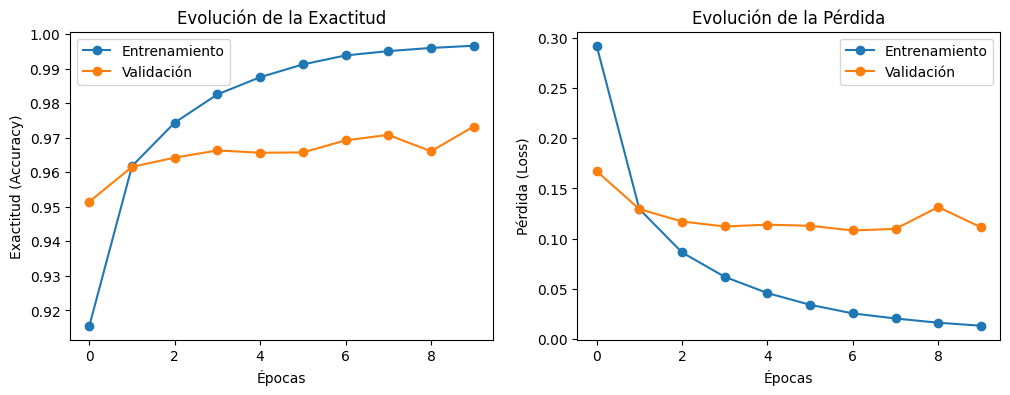

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 3
Este experimento, probaremos a utilizar un optimizador distinto, el descenso de gradiente estocástico (sgd), como tarda mas en aprender que el Adam, lo utilizaremos con 10 épocas.

**Resultados:** obtenemos un accuracy en test ligeramente menor que en los experimentos anteriores y aumentan bastante los errores totales que ha cometido el modelo con los datos de test. En la evolución del modelo con los datos de entrenamiento y de validación podemos ver cómo el modelo aprende de una forma mucho más lenta pero constante, sin llegar a mostrar sobreajuste. Esto nos demuestra que SGD es bastante más lento que Adam y necesitaría un número significativamente mayor de épocas para igualar su rendimiento.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

#Cambiamos el optimizador a sgd
model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
#Seguimos manteniendo las 10 epocas
h=model.fit(x_train, y_train, epochs=10, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8135 - loss: 0.7424 - val_accuracy: 0.8974 - val_loss: 0.3845
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8985 - loss: 0.3671 - val_accuracy: 0.9128 - val_loss: 0.3114
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9116 - loss: 0.3127 - val_accuracy: 0.9225 - val_loss: 0.2783
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9208 - loss: 0.2810 - val_accuracy: 0.9277 - val_loss: 0.2557
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9275 - loss: 0.2575 - val_accuracy: 0.9327 - val_loss: 0.2382
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9328 - loss: 0.2386 - val_accuracy: 0.9380 - val_loss: 0.2237
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9372 - loss: 0.2228 - val_accuracy: 0.9420 - val_loss: 0.2116
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9411 - loss: 0.2092 - 

[0.18236194550991058, 0.9474999904632568]


Tiempo invertido en el entrenamiento: 52.77 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 525 (de 10000 imágenes)


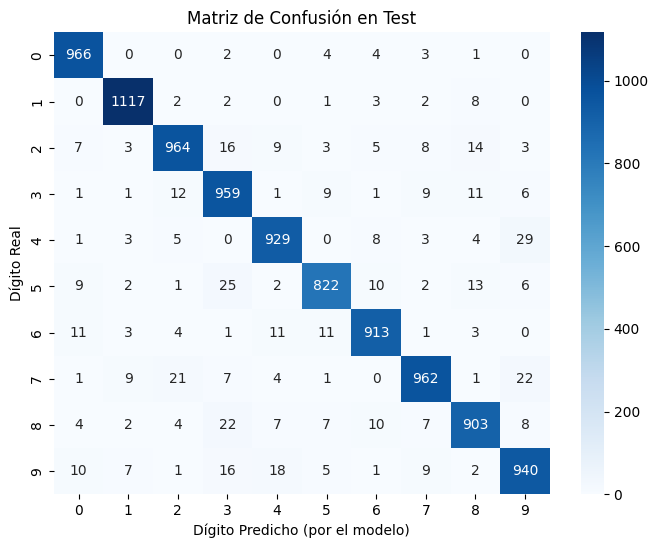

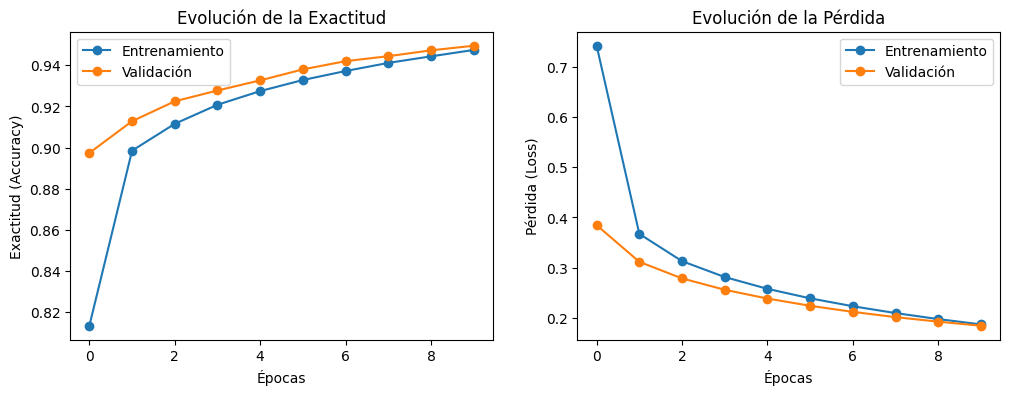

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 4
Este experimento, probaremos a utilizar otro optimizador distinto que es uno de los mas populares, Root Mean Square Propagation (RMSprop) manteniendo la configuración inicial de 5 épocas y un tamaño de lote de 32 para compararlo directamente con Adam.

**Resultados:** muestra un accuracy en test y una perdida similar al del primer experimento, con un total de errores ínfimamente superior y tardando aproximadamente 30 segundos. Al observar las gráficas de evolución, he comprobado que la red aprende de forma muy rápida y vertical desde la primera época, con un comportamiento casi idéntico al del primer experimento. Esto me demuestra que RMSprop, al ajustar dinámicamente la velocidad de aprendizaje para cada parámetro de la misma forma que Adam, es una alternativa igual de eficiente para este problema y supera con creces la lentitud que vimos al usar SGD.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

#Cambiamos el optimizador por RMSprop
model.compile(optimizer='rmsprop',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9178 - loss: 0.2864 - val_accuracy: 0.9507 - val_loss: 0.1695
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9599 - loss: 0.1352 - val_accuracy: 0.9601 - val_loss: 0.1313
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9725 - loss: 0.0951 - val_accuracy: 0.9653 - val_loss: 0.1209
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9788 - loss: 0.0740 - val_accuracy: 0.9669 - val_loss: 0.1172
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9833 - loss: 0.0603 - val_accuracy: 0.9676 - val_loss: 0.1182

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9781 - loss: 0.0720

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9678 - loss: 0.1123


[0.1122937723994255, 0.9678000211715698]


Tiempo invertido en el entrenamiento: 32.95 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 322 (de 10000 imágenes)


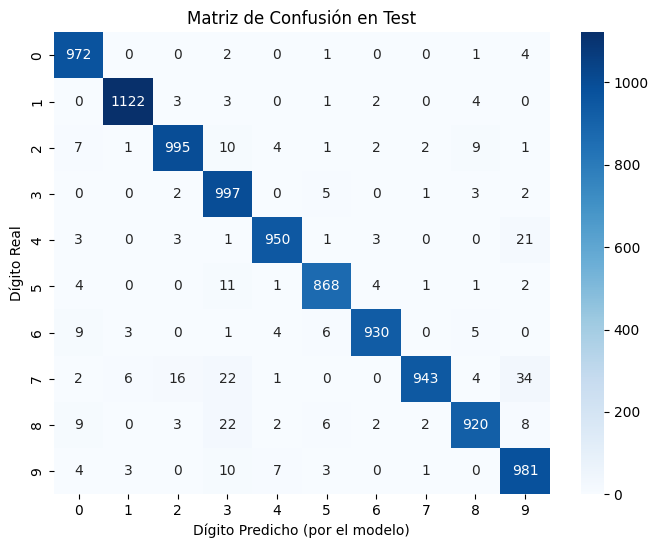

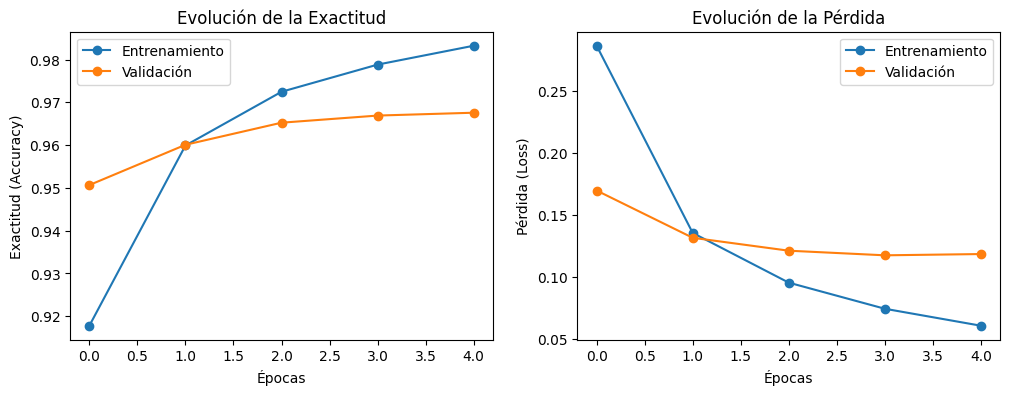

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 5
En este quinto experimento volveremos a utilizar el optimizador Adam y un entrenamiento de 10 épocas, pero introduciremos un cambio drástico en el tamaño del lote (batch_size), aumentándolo del valor por defecto a 1024. El objetivo es comprobar cómo afecta agrupar tantas imágenes en cada paso. Teóricamente, al procesar más de mil imágenes simultáneamente, el tiempo de cálculo por época será rapidísimo; sin embargo, la red actualizará sus pesos matemáticos muchas menos veces por época, lo que puede dificultar que alcance una buena exactitud en el mismo tiempo. Para analizar este efecto, probaremos primero el entrenamiento con 10 épocas y, a continuación, realizaremos una segunda prueba con 20 épocas para comprobar si dándole más oportunidades de actualizar los pesos el modelo logra compensar esa desventaja y alcanzar un buen rendimiento.

**Resultados:** he notado un impacto radical en los tiempos, con un lote de 1024, la prueba inicial de 10 épocas fue increíblemente rápida, pero cometió bastantes más errores que nuestro modelo base, confirmando que la red dio muy pocos pasos para aprender los patrones adecuadamente. Sin embargo, al ampliar a 20 épocas, la exactitud mejoró notablemente y los errores cayeron a niveles muy cercanos a los del primer experimento. Lo más curioso es que, incluso entrenando estas 20 épocas, el tiempo total invertido siguió siendo considerablemente inferior al que tardamos en el experimento inicial de solo 5 épocas. Además, al observar las gráficas, las curvas de aprendizaje se muestran muy suaves y estables, sin ningún rastro del sobreajuste que sufrimos en el segundo experimento. En conclusión, utilizar lotes gigantes acelera enormemente el cómputo gracias a la paralelización, pero nos obliga a compensarlo entrenando durante más épocas para que el modelo tenga tiempo de alcanzar una buena precisión.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
#Añadimos un batch_size de 1024, en vez de 32 por defecto
h=model.fit(x_train, y_train, batch_size=1024, epochs=10, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.7637 - loss: 0.9129 - val_accuracy: 0.8976 - val_loss: 0.3746
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9054 - loss: 0.3404 - val_accuracy: 0.9214 - val_loss: 0.2829
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9240 - loss: 0.2728 - val_accuracy: 0.9337 - val_loss: 0.2412
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9344 - loss: 0.2330 - val_accuracy: 0.9419 - val_loss: 0.2126
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9435 - loss: 0.2038 - val_accuracy: 0.9475 - val_loss: 0.1915
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9499 - loss: 0.1809 - val_accuracy: 0.9518 - val_loss: 0.1755
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9553 - loss: 0.1625 - val_accuracy: 0.9553 - val_loss: 0.1628
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9594 - loss: 0.1472 - val_accuracy: 0.9578 - v

[0.13154801726341248, 0.9617000222206116]


Tiempo invertido en el entrenamiento: 11.54 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 383 (de 10000 imágenes)


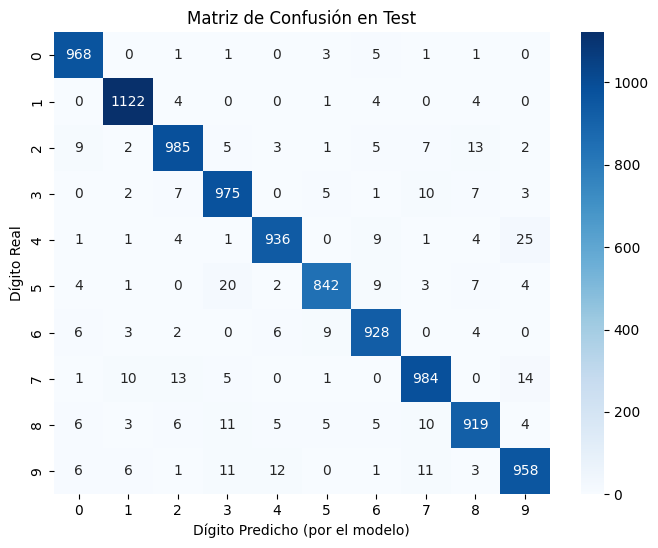

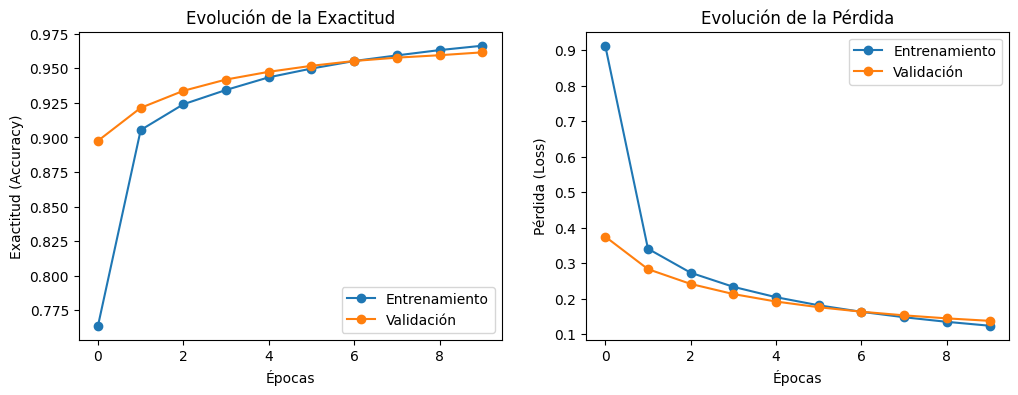

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
#Aumentamos el numero de epocas a 20 para compensar el ritmo de aprendizaje
h=model.fit(x_train, y_train, batch_size=1024, epochs=20, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7697 - loss: 0.8944 - val_accuracy: 0.8938 - val_loss: 0.3752
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9039 - loss: 0.3447 - val_accuracy: 0.9199 - val_loss: 0.2855
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9234 - loss: 0.2771 - val_accuracy: 0.9319 - val_loss: 0.2440
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9342 - loss: 0.2383 - val_accuracy: 0.9398 - val_loss: 0.2163
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9420 - loss: 0.2107 - val_accuracy: 0.9457 - val_loss: 0.1964
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9481 - loss: 0.1895 - val_accuracy: 0.9505 - val_loss: 0.1809
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9528 - loss: 0.1720 - val_accuracy: 0.9539 - val_loss: 0.1686
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9567 - loss: 0.1572 - val_accuracy: 0.9562 - v

[0.09946630150079727, 0.9700000286102295]


Tiempo invertido en el entrenamiento: 21.73 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 300 (de 10000 imágenes)


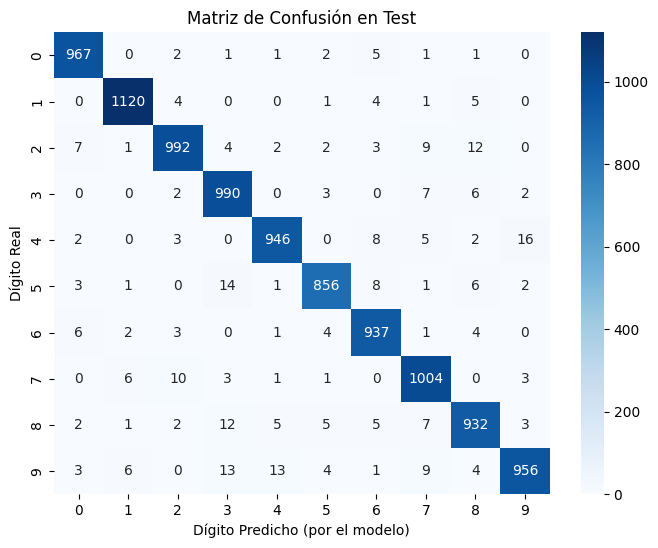

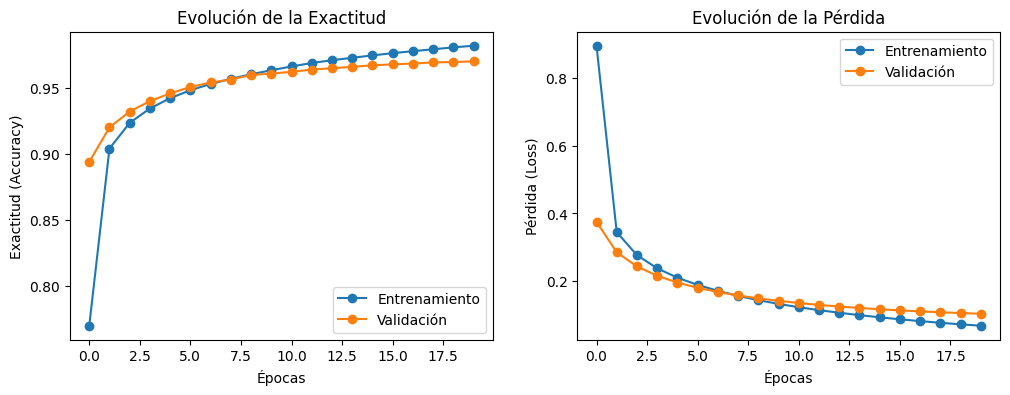

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 6
En contraste directo con el experimento anterior, en esta prueba he decidido reducir el batch_size de su valor por defecto (32) a un número menor, como 16 u 8. El objetivo es observar el efecto de actualizar los pesos de la red neuronal con mucha mayor frecuencia.

**Resultados:** tiempo total de entrenamiento se ha disparado, siendo la prueba más lenta de todas las que hemos realizado hasta ahora. Esto sucede porque, al procesar grupos tan pequeños de imágenes, la red se ve obligada a actualizar sus pesos matemáticos muchísimas más veces por época, perdiendo toda la eficiencia y rapidez de la paralelización. En cuanto a la precisión, aunque el modelo logra un buen rendimiento y comete un número de errores casi idéntico al de nuestro segundo experimento, las gráficas de evolución revelan el mismo problema, sobreajuste. La curva de pérdida en validación se estanca rápidamente mientras que la de entrenamiento sigue disminuyendo, lo que demuestra que la red termina memorizando los datos en lugar de generalizar.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
inicio = time.time()
#Añadimos un batch_size de 1024, en vez de 32 por defecto
h=model.fit(x_train, y_train, batch_size=16, epochs=10, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9265 - loss: 0.2525 - val_accuracy: 0.9567 - val_loss: 0.1533
Epoch 2/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9671 - loss: 0.1086 - val_accuracy: 0.9645 - val_loss: 0.1244
Epoch 3/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9792 - loss: 0.0715 - val_accuracy: 0.9662 - val_loss: 0.1161
Epoch 4/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9852 - loss: 0.0514 - val_accuracy: 0.9675 - val_loss: 0.1150
Epoch 5/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.9899 - loss: 0.0367 - val_accuracy: 0.9668 - val_loss: 0.1169
Epoch 6/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9915 - loss: 0.0287 - val_accuracy: 0.9696 - val_loss: 0.1164
Epoch 7/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9935 - loss: 0.0220 - val_accuracy: 0.9707 - val_loss: 0.1198
Epoch 8/10
3000/3000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9947 - loss: 0

[0.10950478166341782, 0.9743000268936157]


Tiempo invertido en el entrenamiento: 130.45 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 257 (de 10000 imágenes)


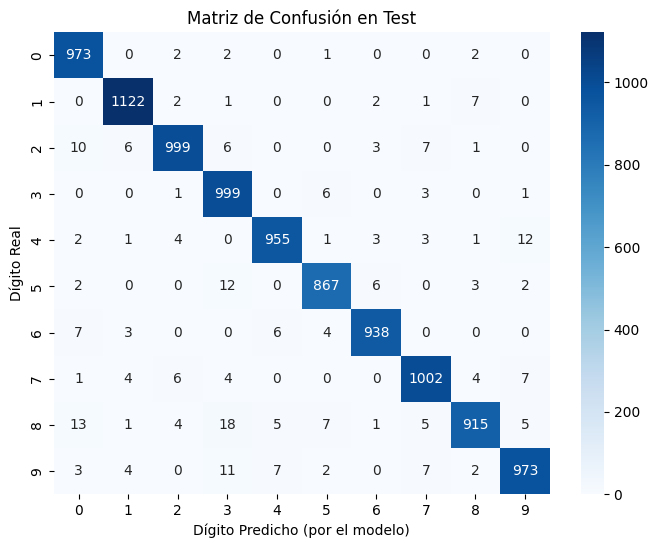

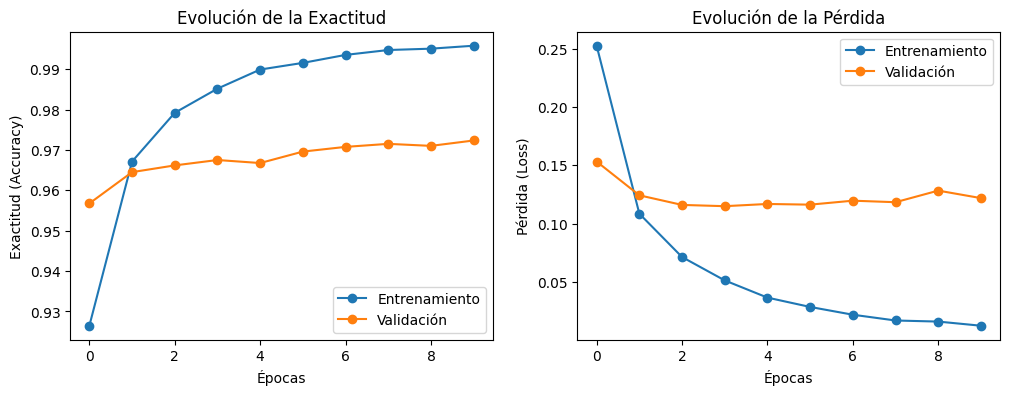

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 6
En este experimento he decidido alterar un parámetro de la tasa de aprendizaje. Utilizando de nuevo el optimizador Adam, he cambiado su configuración por defecto para forzar una tasa inusualmente alta (learning_rate=0.05). El objetivo es comprobar qué sucede cuando obligamos a la red neuronal a dar "pasos" de ajuste demasiado grandes en cada actualización de sus pesos.

**Resultados:** se aprecia una caída dramática en el rendimiento, con una exactitud que apenas supera el 87% y un incremento masivo en la cantidad de errores, superando los mil fallos. Al observar las gráficas, el desastre matemático se hace evidente: en lugar de mostrar las curvas suaves y descendentes que veíamos en los primeros experimentos, aquí la pérdida de entrenamiento y validación rebota de forma errática de una época a otra. Esto confirma que al obligar a la red a dar saltos tan grandes en la actualización de sus pesos, el modelo se vuelve completamente inestable y es incapaz de encontrar el punto óptimo para clasificar correctamente los dígitos.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

#Modificamos el learning rate pasandole explicitamente el parametro a la función.
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.05),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8581 - loss: 0.5802 - val_accuracy: 0.8598 - val_loss: 0.5421
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8719 - loss: 0.5628 - val_accuracy: 0.8718 - val_loss: 0.5938
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8708 - loss: 0.5425 - val_accuracy: 0.8866 - val_loss: 0.5564
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8671 - loss: 0.5541 - val_accuracy: 0.8677 - val_loss: 0.5575
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8736 - loss: 0.5243 - val_accuracy: 0.8694 - val_loss: 0.5582

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8712 - loss: 0.5161

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8684 - loss: 0.5895


[0.5894906520843506, 0.868399977684021]


Tiempo invertido en el entrenamiento: 35.48 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Número total de errores en test: 1316 (de 10000 imágenes)


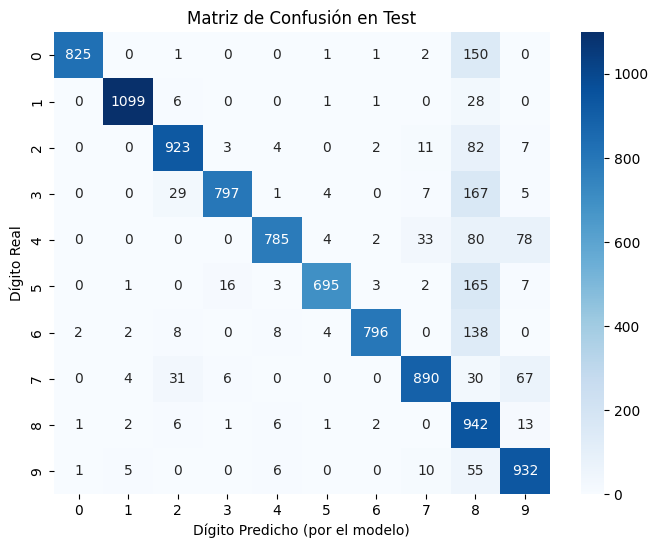

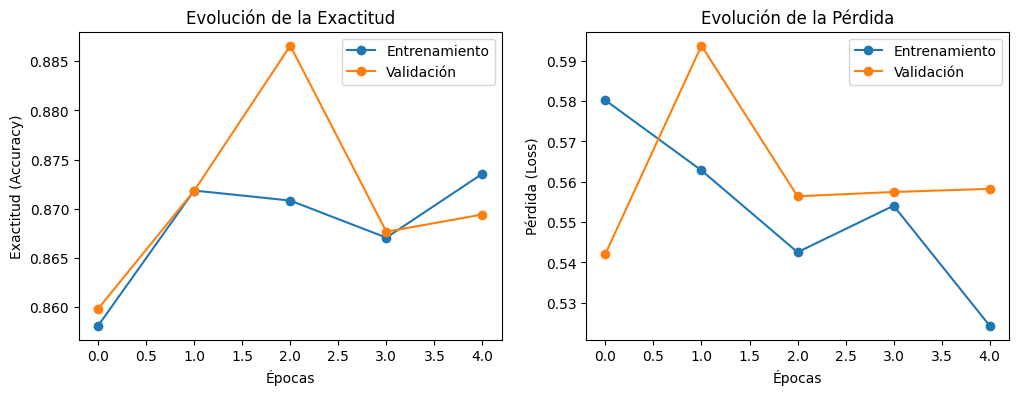

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 7
En este experimento he decidido modificar la función de activación de la capa oculta. Manteniendo los parámetros base del primer experimento, sustituiremos la función relu por la clásica función sigmoid y en otro intento por la tahn. El objetivo es observar cómo afecta la transformación matemática dentro de las neuronas al proceso de aprendizaje.

**Resultados:** resulta evidente que a la función sigmoid le cuesta arrancar, si observamos el accuracy durante en el entrenamiento podemos observar que tiene un aprendizaje más lento en las primeras épocas y acumulando una mayor cantidad de errores al finalizar el entrenamiento en el conjunto de test. Por el contrario, la función tanh se comporta de forma mucho más directa y ágil desde el primer paso, logrando reducir significativamente los fallos frente a la sigmoide. No obstante, al comparar estas dos opciones clásicas con nuestro primer experimento, confirmo que la función relu original sigue siendo la alternativa más equilibrada y eficiente en su convergencia.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

#Cambiamos la funcion de activacion de la capa oculta
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='sigmoid'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8862 - loss: 0.4436 - val_accuracy: 0.9299 - val_loss: 0.2416
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9364 - loss: 0.2184 - val_accuracy: 0.9477 - val_loss: 0.1850
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9522 - loss: 0.1635 - val_accuracy: 0.9553 - val_loss: 0.1551
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9626 - loss: 0.1285 - val_accuracy: 0.9603 - val_loss: 0.1360
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9703 - loss: 0.1037 - val_accuracy: 0.9636 - val_loss: 0.1229

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9719 - loss: 0.0970

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9642 - loss: 0.1161


[0.11612777411937714, 0.9642000198364258]


Tiempo invertido en el entrenamiento: 34.18 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 358 (de 10000 imágenes)


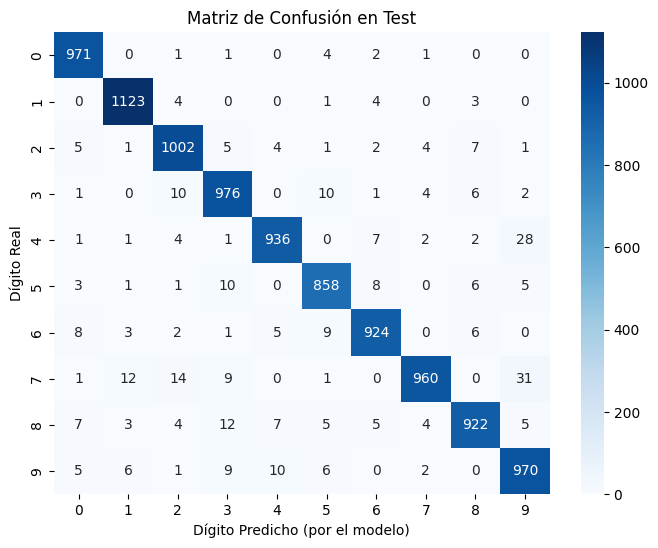

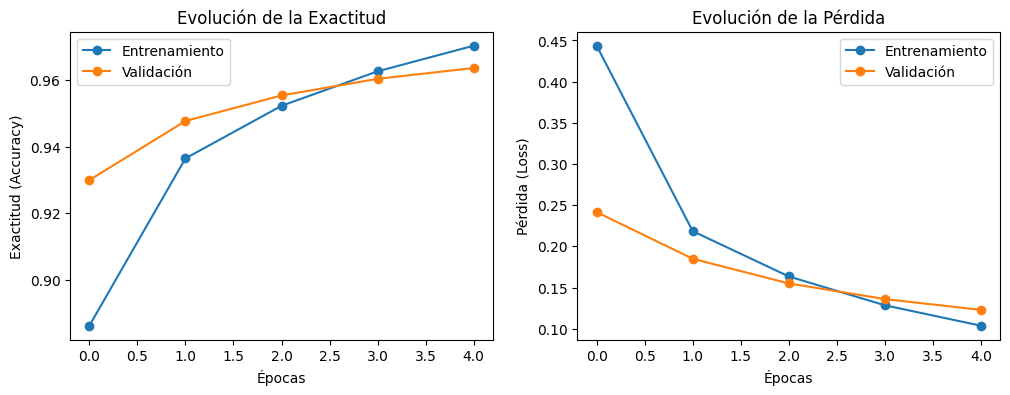

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

#Cambiamos la funcion de activacion de la capa oculta
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='tanh'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9095 - loss: 0.3115 - val_accuracy: 0.9439 - val_loss: 0.1918
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9545 - loss: 0.1539 - val_accuracy: 0.9555 - val_loss: 0.1481
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.9691 - loss: 0.1053 - val_accuracy: 0.9617 - val_loss: 0.1279
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9783 - loss: 0.0770 - val_accuracy: 0.9650 - val_loss: 0.1145
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9841 - loss: 0.0573 - val_accuracy: 0.9675 - val_loss: 0.1051

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9813 - loss: 0.0629

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9684 - loss: 0.1005


[0.10047437995672226, 0.9684000015258789]


Tiempo invertido en el entrenamiento: 51.52 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 316 (de 10000 imágenes)


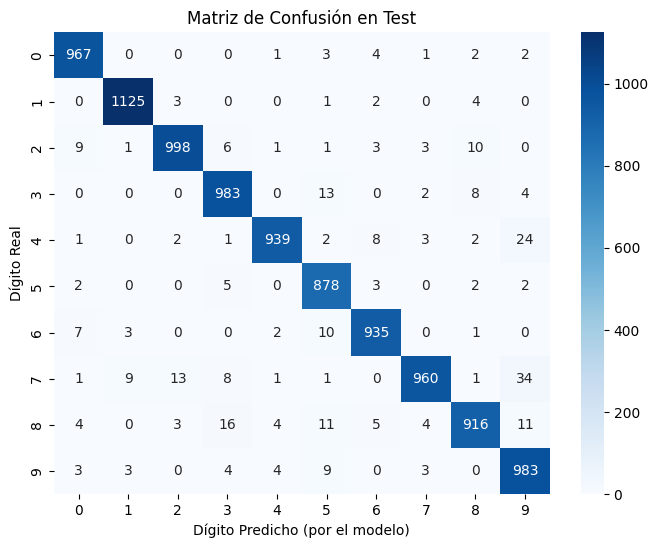

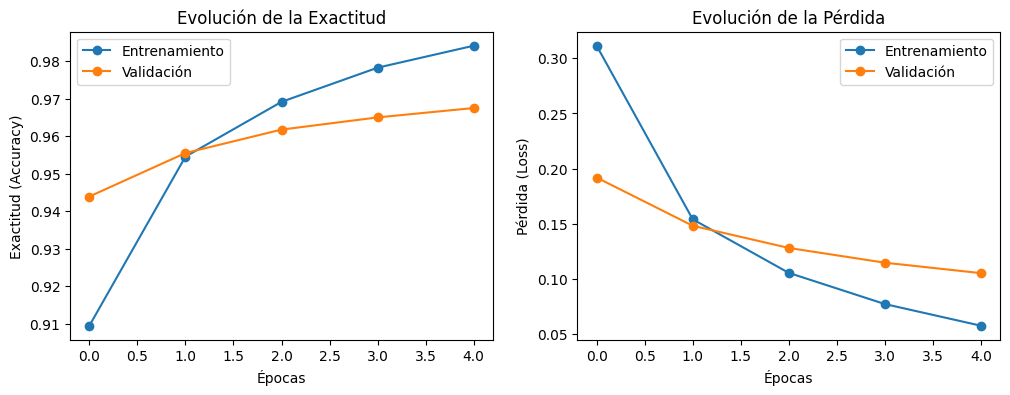

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 8
En este experimento volveremos a la configuración base del experimento 1 (el mejor hasta ahora) pero reduciremos la capa oculta principal de 128 a tan solo 16 neuronas. El objetivo es crear un "cuello de botella" de información para comprobar qué sucede cuando limitamos severamente la capacidad de cálculo del modelo.

**Resultados:** el tiempo de entrenamiento se ha reducido de forma evidente debido a la menor cantidad de parámetros matemáticos que la red debe calcular. Sin embargo, al crear este "cuello de botella", la exactitud final ha caído considerablemente, dado que la cantidad de errores en el conjunto de test se ha duplicado. Aunque las gráficas de evolución muestran que el modelo sigue aprendiendo de forma constante y sin signos de sobreajuste, al dejar la red con una capacidad mas limitada, le quitamos parte de la capacidad que tiene para extraer y comprender los detalles sutiles de los dígitos.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

#Reducimos las neuronas de la capa oculta
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(16, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8590 - loss: 0.5050 - val_accuracy: 0.9237 - val_loss: 0.2627
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9288 - loss: 0.2476 - val_accuracy: 0.9360 - val_loss: 0.2202
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9399 - loss: 0.2111 - val_accuracy: 0.9427 - val_loss: 0.2011
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9448 - loss: 0.1906 - val_accuracy: 0.9463 - val_loss: 0.1903
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9488 - loss: 0.1766 - val_accuracy: 0.9482 - val_loss: 0.1819

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9509 - loss: 0.1674

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9462 - loss: 0.1876


[0.18764762580394745, 0.9462000131607056]


Tiempo invertido en el entrenamiento: 21.65 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 538 (de 10000 imágenes)


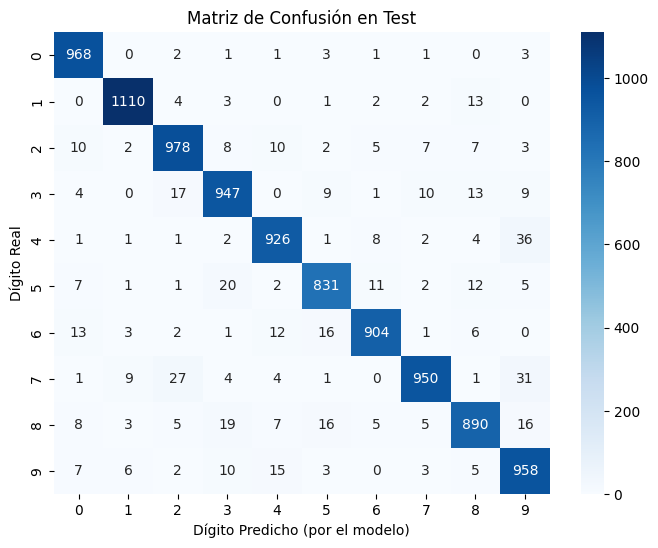

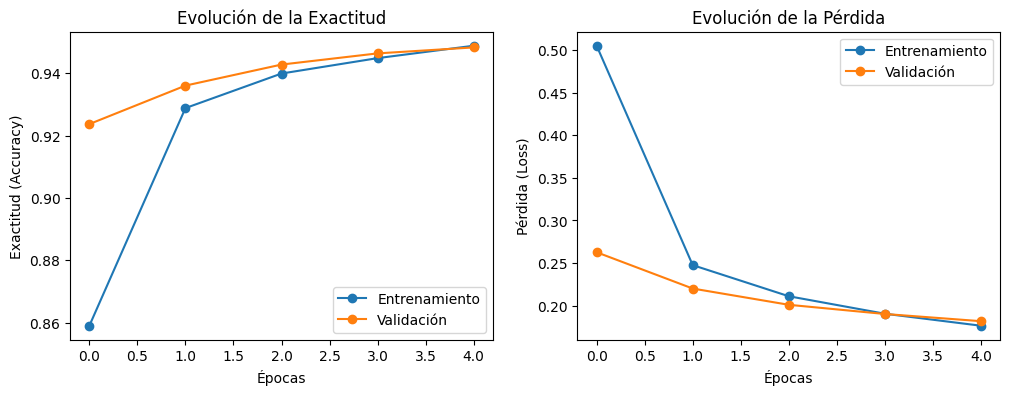

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Experimento 9
En este experimento haremos lo opuesto al anterior, ampliando la capa oculta principal de 128 a 512 neuronas. El objetivo es comprobar si al dotar al modelo de capacidad logramos mejorar su precisión.

**Resultados:** ha elevado considerablemente el tiempo de entrenamiento, tardando casi el doble que nuestro modelo base debido al aumento masivo de cálculos matemáticos. A cambio de este mayor coste computacional, el modelo ha logrado una exactitud superior y ha reducido la cantidad de errores totales, respecto al experimento anterior. No obstante, las gráficas de evolución confirman que la curva de pérdida de validación se estanca muy pronto, mientras que la entrenamiento sigue bajando. Esto nos indica que el modelo tiende a memorizar la información muy rápido, es decir, está sobreajustando.

In [ ]:
np.random.seed(0)
tf.random.set_seed(0)

#Aumentamos el numero de neuronas de la capa oculta
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(512, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

inicio = time.time()
h=model.fit(x_train, y_train, epochs=5, validation_split=0.2)
fin = time.time()

print ("\nEvaluamos modelo con los valores de entrenamiento")
model.evaluate(x_train, y_train)
print ("\nEvaluamos modelo con los valores de test")
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9334 - loss: 0.2235 - val_accuracy: 0.9627 - val_loss: 0.1268
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9728 - loss: 0.0889 - val_accuracy: 0.9633 - val_loss: 0.1181
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9849 - loss: 0.0534 - val_accuracy: 0.9678 - val_loss: 0.1038
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9902 - loss: 0.0347 - val_accuracy: 0.9684 - val_loss: 0.1086
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9928 - loss: 0.0243 - val_accuracy: 0.9703 - val_loss: 0.1045

Evaluamos modelo con los valores de entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9866 - loss: 0.0421

Evaluamos modelo con los valores de test
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9735 - loss: 0.0921


[0.0920824259519577, 0.9735000133514404]


Tiempo invertido en el entrenamiento: 60.77 segundos
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Número total de errores en test: 265 (de 10000 imágenes)


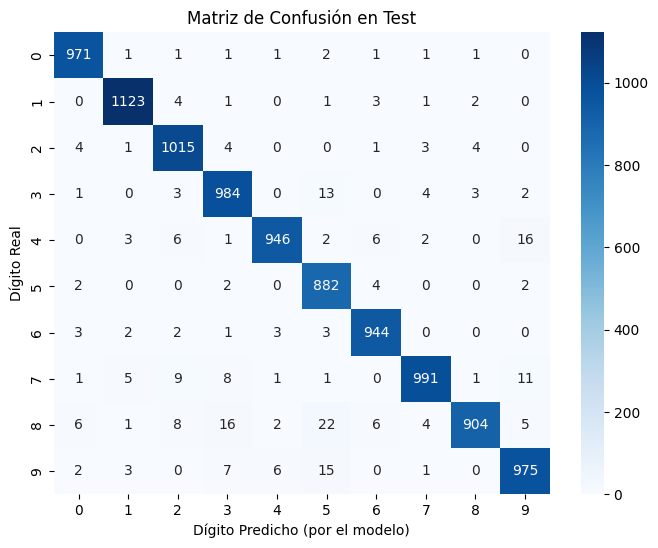

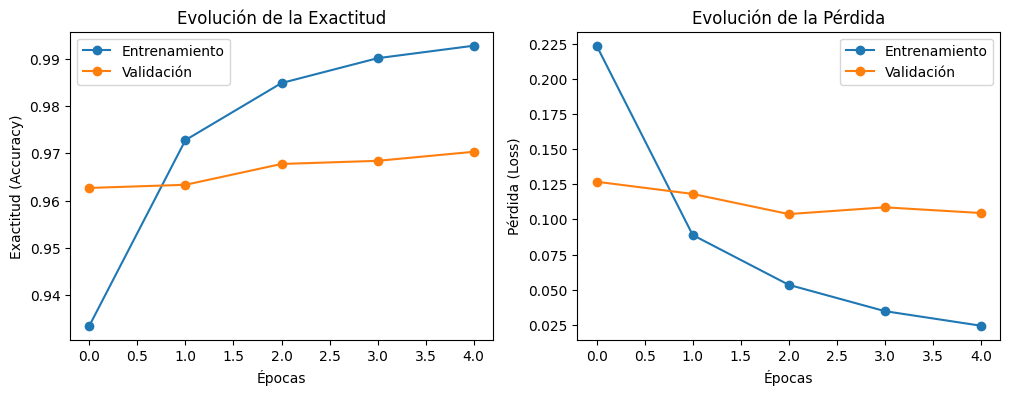

In [ ]:
tiempo_entrenamiento = fin - inicio
print(f"\nTiempo invertido en el entrenamiento: {tiempo_entrenamiento:.2f} segundos")
numeroErroresMatrizConfusion(model, x_test, y_test)
grafica_accuracy_perdida(h);

# Resultados finales
Tras someter la arquitectura a diversas modificaciones de hiperparámetros (optimizadores, épocas, tamaño de lote, funciones de activación y número de neuronas), podemos extraer dos grandes conclusiones para este conjunto de datos (MNIST):

El modelo más equilibrado: La configuración inicial del experimento 1 (Optimizador Adam, Batch Size 32, Activación ReLU, 128 neuronas y 5 épocas) ha demostrado ser el punto de partida más robusto. Logra una exactitud excelente sin caer en el sobreajuste, demostrando que la red generaliza los patrones visuales correctamente en un tiempo de ejecución estándar.

El modelo más eficiente: Si el objetivo es optimizar el rendimiento computacional sin sacrificar la exactitud, el uso de un tamaño de lote gigante (1024) compensado con un mayor número de épocas (20), experimento 5, ha resultado ser la mejor estrategia técnica. La enorme paralelización del cálculo permitió que la red terminara de entrenar en menos tiempo que el modelo base, igualando sus resultados de precisión y manteniendo curvas de aprendizaje completamente estables.